# Лабораторная работа 12

Тема: **Vanilla GAN для генерации цифр MNIST в PyTorch**  
Формат: практическая работа с обязательными собственными экспериментами и комментариями.

> Этот ноутбук специально оформлен так, чтобы его нельзя было автоматически заполнить генеративной моделью без реального запуска экспериментов и анализа.  
> Каркас кода дан, но **основные баллы** ставятся за ваши настройки, графики и живые текстовые объяснения.


## 1. Ваше понимание задачи GAN (если не знаетет, что такое GAN - можно гуглить и спрашивать LLM)

Перед запуском кода опишите текущее понимание (8–12 предложений):

1. Для чего нужны генеративно‑состязательные сети (GAN) и чем их цель отличается от классической задачи классификации.  
2. Как вы интуитивно представляете «игру» генератора и дискриминатора: кто что пытается сделать и почему это неустойчивая задача.  
3. Каких визуальных артефактов вы ожидаете от **простого** Vanilla GAN на MNIST (размытость, странные гибриды цифр и т.п.).

Пишите своими словами, как если бы объясняли задачу одногруппнику.


In [ ]:
intro_text = """
1. Генеративно-состязательные сети это две нейронных сети, которые противодействуют другую.
Цель - генерация новых данных, которые имитируют образцы реального датасета.
2. Одна сеть как бы старается обмануть другую. Генератор выдает пытается обмануть дескриптор, подав сгенерированные данные за данные из датасета,
а дескриптор пытается отличить сгенерированные данные от настоящих.
3. Зашумленность, размытость, странные изображения, не похожие на цифры.
"""
print(intro_text)

## 2. Импорт, настройки и данные (MNIST)


In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils

import matplotlib.pyplot as plt
import numpy as np
import os

MY_SEED = 2  # при своих экспериментах можете поменять, но зафиксируйте в отчёте
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
print("MY_SEED =", MY_SEED)

# каталог для возможного сохранения картинок
os.makedirs("gan_samples", exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # пиксели в [-1, 1]
])

batch_size = 128

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
print("Размер train:", len(train_dataset))

Устройство: cpu
MY_SEED = 2
Размер train: 60000


Посмотрим на несколько реальных изображений, которые GAN должен научиться имитировать.


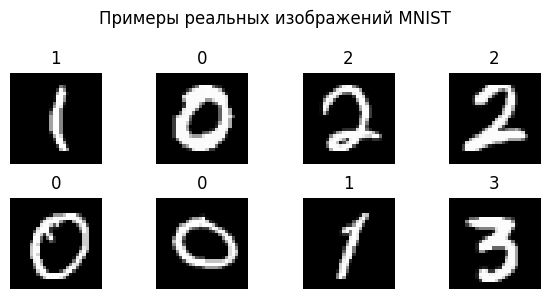

In [2]:
real_images, real_labels = next(iter(train_loader))
plt.figure(figsize=(6, 3))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(real_images[i].squeeze(0), cmap="gray")
    plt.title(str(real_labels[i].item()))
    plt.axis("off")
plt.suptitle("Примеры реальных изображений MNIST")
plt.tight_layout()
plt.show()

### Мини‑комментарий по данным

Кратко (3–5 предложений) опишите:
- насколько, на ваш взгляд, легко/сложно генератору научиться имитировать такие цифры;  
- какие особенности рукописных цифр могут затруднить генерацию (разные стили, толщина линий и т.п.).


In [10]:
data_comment = """
1. Думаю научиться генерировать такие цифры несложно. Размеры изображения небольшие, само изображение черно-белое. Всего 10 классов цифр.
2. Думаю разные стили написания действительно могут затруднить генерацию.
"""
print(data_comment)


1. Думаю научиться генерировать такие цифры несложно. Размеры изображения небольшие, само изображение черно-белое. Всего 10 классов цифр.
2. Думаю разные стили написания действительно могут затруднить генерацию.



## 3. Архитектура генератора и дискриминатора

Используем классический Vanilla GAN с полносвязными сетями:
- Генератор: принимает случайный шум `z` размерности 100 и выдаёт изображение 28×28 (через `tanh`, в диапазоне [-1, 1]);  
- Дискриминатор: принимает изображение 28×28 и выдаёт вероятность того, что оно "реальное".


In [4]:
z_dim = 100
img_dim = 28 * 28

class Generator(nn.Module):
    def __init__(self, z_dim, img_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.BatchNorm1d(256),

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.BatchNorm1d(512),

            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.BatchNorm1d(1024),

            nn.Linear(1024, img_dim),
            nn.Tanh()
        )

    def forward(self, z):
        img = self.net(z)
        img = img.view(-1, 1, 28, 28)
        return img


class Discriminator(nn.Module):
    def __init__(self, img_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


G = Generator(z_dim, img_dim).to(device)
D = Discriminator(img_dim).to(device)

print(G)
print(D)

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=256, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=512, out_features=1024, bias=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): Linear(in_features=1024, out_features=784, bias=True)
    (10): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, 

### Краткий анализ архитектуры

Ответьте в 4–6 предложениях:
- почему в генераторе используется `tanh` на выходе и совместим ли он с нормализацией входных данных;  
- зачем в дискриминаторе используется `LeakyReLU`, а не обычный `ReLU`.


In [11]:
arch_comment = """
1. tanh масштабирует значения пикселей в диапазон от -1 до 1. Естественно он совместим с нормализацией входных данных.
2. LeakyReLU относится лояльнее к значениям меньше 0.
"""
print(arch_comment)


1. tanh масштабирует значения пикселей в диапазон от -1 до 1. Естественно он совместим с нормализацией входных данных.
2. LeakyReLU относится лояльнее к значениям меньше 0.



## 4. Функция потерь, оптимизаторы и фиксированный шум

Используем бинарную кросс‑энтропию и два оптимизатора Adam (для G и D).


In [6]:
criterion = nn.BCELoss()

lr = 2e-4
beta1 = 0.5

opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999))

# фиксированный шум для отслеживания прогресса генератора
fixed_z = torch.randn(64, z_dim, device=device)
print("fixed_z shape:", fixed_z.shape)

fixed_z shape: torch.Size([64, 100])


## 5. Цикл обучения GAN с журналированием лоссов

На каждой итерации:

1. Обновляем дискриминатор: считаем лосс на реальных и сгенерированных изображениях.  
2. Обновляем генератор: генерируем фейки и стараемся заставить дискриминатор считать их реальными.


Эпоха 1/30 | loss_G=1.2023, loss_D=0.8226


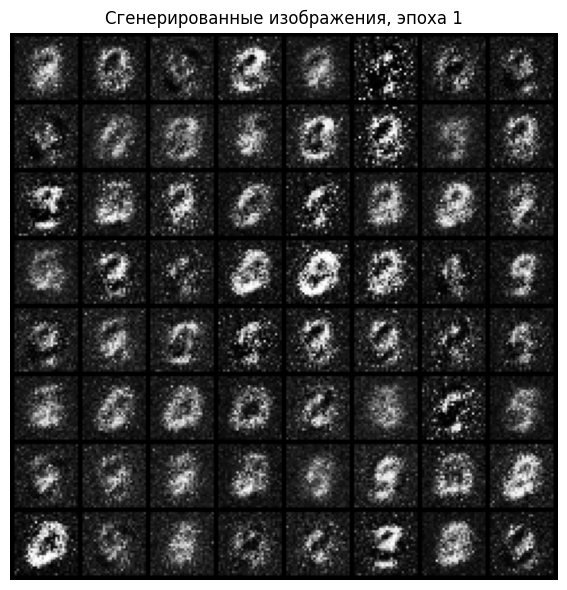

Эпоха 2/30 | loss_G=0.8358, loss_D=1.2477
Эпоха 3/30 | loss_G=0.8542, loss_D=1.2568
Эпоха 4/30 | loss_G=0.8625, loss_D=1.2568
Эпоха 5/30 | loss_G=0.8437, loss_D=1.2763


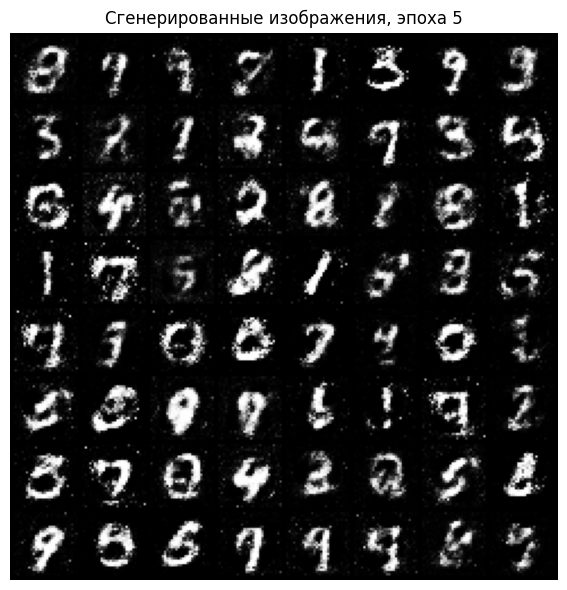

Эпоха 6/30 | loss_G=0.8197, loss_D=1.2931
Эпоха 7/30 | loss_G=0.8014, loss_D=1.3102
Эпоха 8/30 | loss_G=0.7844, loss_D=1.3224
Эпоха 9/30 | loss_G=0.7796, loss_D=1.3254
Эпоха 10/30 | loss_G=0.7772, loss_D=1.3300


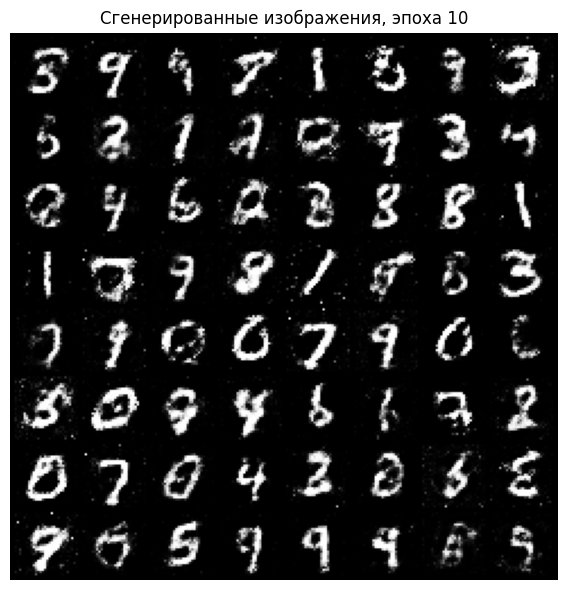

Эпоха 11/30 | loss_G=0.7684, loss_D=1.3369
Эпоха 12/30 | loss_G=0.7641, loss_D=1.3409
Эпоха 13/30 | loss_G=0.7611, loss_D=1.3431
Эпоха 14/30 | loss_G=0.7603, loss_D=1.3454
Эпоха 15/30 | loss_G=0.7590, loss_D=1.3473


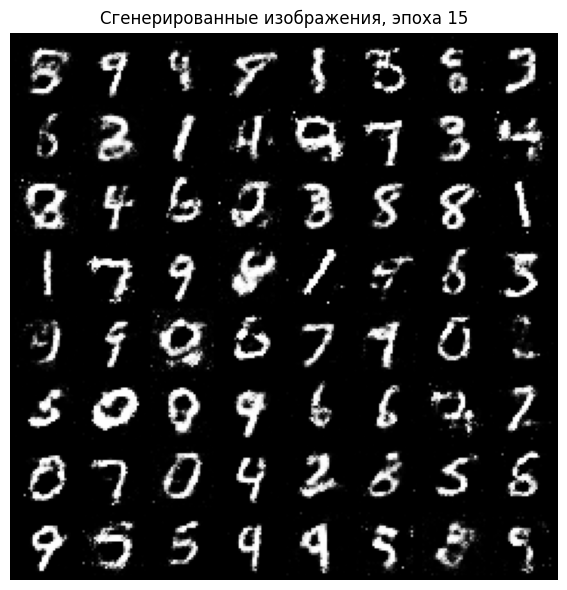

Эпоха 16/30 | loss_G=0.7562, loss_D=1.3494
Эпоха 17/30 | loss_G=0.7560, loss_D=1.3502
Эпоха 18/30 | loss_G=0.7581, loss_D=1.3509
Эпоха 19/30 | loss_G=0.7549, loss_D=1.3502
Эпоха 20/30 | loss_G=0.7560, loss_D=1.3499


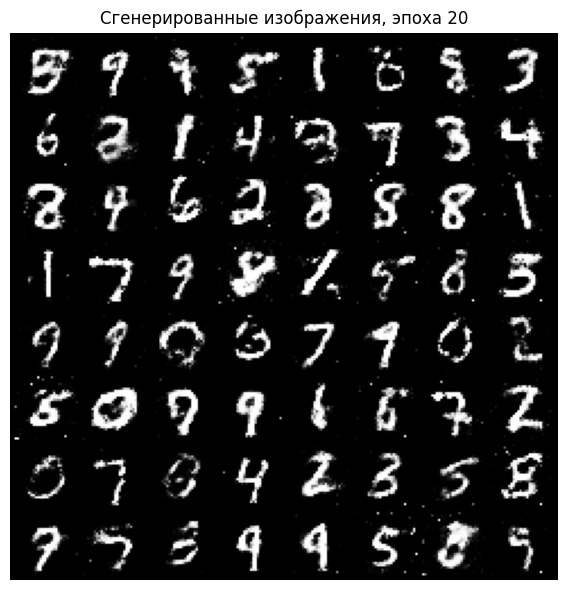

Эпоха 21/30 | loss_G=0.7551, loss_D=1.3483
Эпоха 22/30 | loss_G=0.7595, loss_D=1.3493
Эпоха 23/30 | loss_G=0.7584, loss_D=1.3481
Эпоха 24/30 | loss_G=0.7553, loss_D=1.3501
Эпоха 25/30 | loss_G=0.7561, loss_D=1.3494


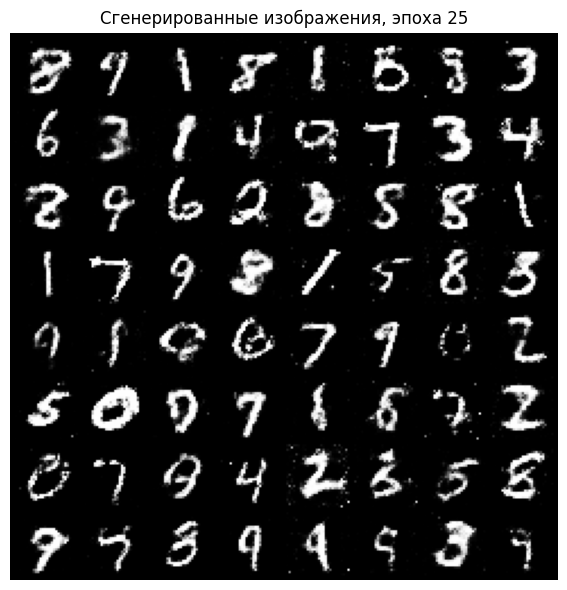

Эпоха 26/30 | loss_G=0.7595, loss_D=1.3481
Эпоха 27/30 | loss_G=0.7570, loss_D=1.3493
Эпоха 28/30 | loss_G=0.7593, loss_D=1.3484
Эпоха 29/30 | loss_G=0.7590, loss_D=1.3476
Эпоха 30/30 | loss_G=0.7582, loss_D=1.3491


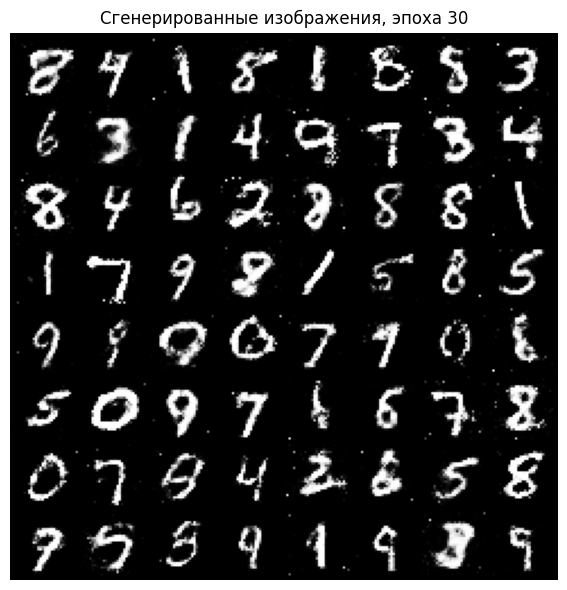

In [7]:
def train_gan(num_epochs):
    G.train()
    D.train()

    loss_history_G = []
    loss_history_D = []

    for epoch in range(1, num_epochs + 1):
        epoch_loss_G = 0.0
        epoch_loss_D = 0.0
        n_batches = 0

        for real_imgs, _ in train_loader:
            real_imgs = real_imgs.to(device)
            bs = real_imgs.size(0)

            # --- шаг дискриминатора ---
            real_labels = torch.ones(bs, 1, device=device)
            fake_labels = torch.zeros(bs, 1, device=device)

            # реал
            D_real = D(real_imgs)
            loss_D_real = criterion(D_real, real_labels)

            # фейк (detach, чтобы не обновлять G)
            z = torch.randn(bs, z_dim, device=device)
            fake_imgs = G(z).detach()
            D_fake = D(fake_imgs)
            loss_D_fake = criterion(D_fake, fake_labels)

            loss_D = loss_D_real + loss_D_fake

            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # --- шаг генератора ---
            z = torch.randn(bs, z_dim, device=device)
            fake_imgs = G(z)
            D_fake_for_G = D(fake_imgs)
            loss_G = criterion(D_fake_for_G, real_labels)  # хотим метку 1 для фейков

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            n_batches += 1

        avg_loss_G = epoch_loss_G / n_batches
        avg_loss_D = epoch_loss_D / n_batches
        loss_history_G.append(avg_loss_G)
        loss_history_D.append(avg_loss_D)

        print(f"Эпоха {epoch}/{num_epochs} | loss_G={avg_loss_G:.4f}, loss_D={avg_loss_D:.4f}")

        # визуальный мониторинг качества генератора
        if epoch % 5 == 0 or epoch == 1:
            G.eval()
            with torch.no_grad():
                samples = G(fixed_z).cpu()
            G.train()

            grid = utils.make_grid(samples, nrow=8, normalize=True, value_range=(-1, 1))
            plt.figure(figsize=(6, 6))
            plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
            plt.axis("off")
            plt.title(f"Сгенерированные изображения, эпоха {epoch}")
            plt.tight_layout()
            plt.show()

    return loss_history_G, loss_history_D

num_epochs = 30  # в отчёте попробуйте другие значения и сравните
loss_G, loss_D = train_gan(num_epochs)

## 6. Графики лоссов генератора и дискриминатора

Посмотрим, как ведут себя лоссы G и D по эпохам.


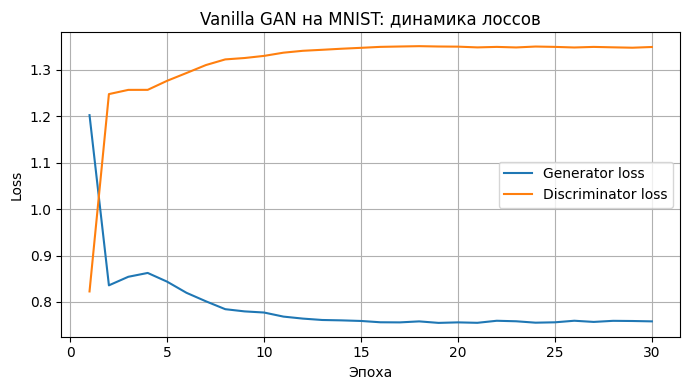

In [8]:
epochs_arr = np.arange(1, num_epochs + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_arr, loss_G, label="Generator loss")
plt.plot(epochs_arr, loss_D, label="Discriminator loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Vanilla GAN на MNIST: динамика лоссов")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Анализ кривых лоссов

Опишите:
- есть ли тенденция к какому‑то «равновесию» между лоссами генератора и дискриминатора;  
- наблюдаются ли периодические колебания (кто «побеждает» на разных этапах обучения);  
- насколько реальное поведение лоссов совпало с вашими ожиданиями из раздела 1.


In [ ]:
loss_comment = """
1. Тенденции к равенству нет, но это и ожидаемо, потому что сети выполняют диаметрально разные задачи.
В нашем случае, после внесения изменений в архитектуру, генератор стал работать куда лучше, создавая достаточно похожие картинки. 
Естественно дескриптору стало достаточно сложно отличать сгенерированные данные.
2. На первой эпохе, пока генератор недостаточно обучился, "выигрывал" дескриптор, легко отличая данные. 
Но, начиная со 2 эпохи, генератор обучился и стал "выигрывать" у дескриптора. 
После 2 эпохи генератор стал достаточно плавно улучшать свои генерации.
3. Ожидания совпали с реальностью.
"""
print(loss_comment)

## 7. Финальная генерация изображений и визуальная оценка

Сгенерируем новые изображения из случайного шума и посмотрим, насколько они похожи на реальный MNIST.


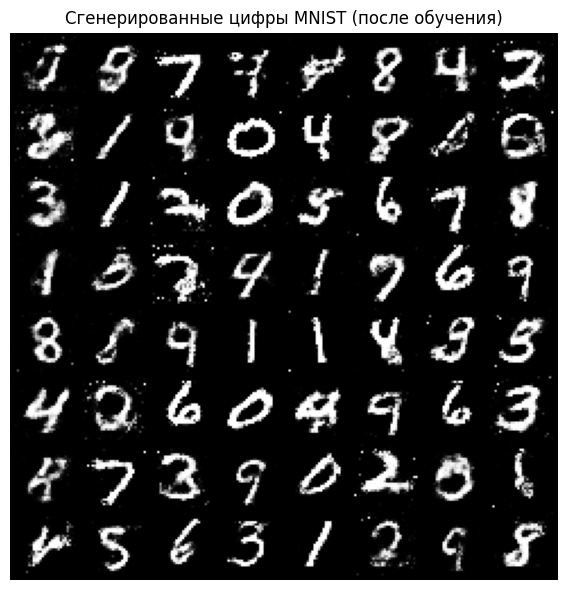

In [9]:
G.eval()
with torch.no_grad():
    z = torch.randn(64, z_dim, device=device)
    gen_imgs = G(z).cpu()

grid = utils.make_grid(gen_imgs, nrow=8, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(6, 6))
plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
plt.axis("off")
plt.title("Сгенерированные цифры MNIST (после обучения)")
plt.tight_layout()
plt.show()

### Оценка качества сгенерированных цифр

Опишите:
- какие цифры получаются наиболее убедительными, а какие чаще всего выглядят как «шум» или гибриды;  
- встречаются ли явно «несуществующие» объекты, не похожие ни на одну цифру, и как часто;  
- как вы думаете, на что сильнее всего влияет качество: глубина сетей, размер `z_dim`, число эпох, баланс обучения G/D.


In [ ]:
gen_quality_comment = """
1. Достаточно много цифр получаются убедительно. Например 0, 1, 3, 4, 6, 8, 9. 
Цифры 2, 5, 7 получаются более зашумленными, иногда трансформируясь в просто набор пикселей.
2. Да, такие генерации тоже встречаются, но достаточно нечасто. Из представленных выше чисел, всего 5-6 картинок, которые сложно определить как цифры.
3. Думаю сильнее всего влияет архитектура сети, z_dim.
"""
print(gen_quality_comment)

## 8. Идеи для вариаций в вашей работе

В **своём** варианте вы должны:

- попробовать **минимум две вариации** архитектуры (например, изменить размеры слоёв в G/D, добавить BatchNorm1d в генератор или заменить ReLU на LeakyReLU, добавить Dropout в дискриминатор) и сравнить визуально качество сгенерированных цифр;  
- поэкспериментировать с `z_dim` (например, 40-50-100) и описать, как это влияет на разнообразие и качество;  
- изменить число эпох/learning rate (возможно, задать разные lr для дискриминатора и генератора) и описать, как меняется динамика лоссов и итоговый результат.

In [12]:
final_summary = """
1. В изначальной архитектуре качество генерации было плохим, что обуславливало "победу" дескриптора. 
После небольшого изменения архитектуры (в генератое добавление BatchNorm1d и замена ReLU на LeakyReLU, в дескрипторе добавлени Dropout) генератор стал показывать 
себя куда лучше, быстро обучившись (уже ко второй эпохе начал генерировать изображения приемлемого качества)
2. z_dim влияет на объем информации, доступный генератору. Чем выше этот z_dim, тем больше данных в виде признаков генератор может обработать 
и преобразовать в выходные данные. Увеличение этого параметра приводит к увеличению качества модели, но так же увеличивает и необходимые вычислительные мощности.
"""
print(final_summary)


1. В изначальной архитектуре качество генерации было плохим, что обуславливало "победу" дескриптора. 
После небольшого изменения архитектуры (в генератое добавление BatchNorm1d и замена ReLU на LeakyReLU, в дескрипторе добавлени Dropout) генератор стал показывать 
себя куда лучше, быстро обучившись (уже ко второй эпохе начал генерировать изображения приемлемого качества)
2. z_dim влияет на объем информации, доступный генератору. Чем выше этот z_dim, тем больше данных в виде признаков генератор может обработать 
и преобразовать в выходные данные. Увеличение этого параметра приводит к увеличению качества модели, но так же увеличивает и необходимые вычислительные мощности.

